In [58]:
from sklearn.preprocessing import StandardScaler
!pip install PCA

In [74]:
from sklearn.decomposition import PCA

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('IPL_Matches_tail_300.csv')
df.head()

,Unnamed: 0.1,Unnamed: 0,date,season,city,venue,team1,team2,toss_winner,toss_decision,...,player_of_match,match_referee,umpire1,umpire2,tv_umpire,reserve_umpire,overs_limit,team1_players,team2_players,winner_encoded
0,0,0,20-05-2022,2022,Mumbai,"Brabourne Stadium, Mumbai",Chennai Super Kings,Rajasthan Royals,Chennai Super Kings,bat,...,R Ashwin,M Nayyar,CB Gaffaney,NA Patwardhan,YC Barde,PG Pathak,20,"RD Gaikwad, DP Conway, MM Ali, N Jagadeesan, A...","YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...",8
1,1,1,21-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Delhi Capitals,Mumbai Indians,Mumbai Indians,field,...,JJ Bumrah,J Srinath,Nitin Menon,Tapan Sharma,HAS Khalid,GR Sadashiv Iyer,20,"PP Shaw, DA Warner, MR Marsh, RR Pant, SN Khan...","Ishan Kishan, RG Sharma, D Brevis, Tilak Varma...",5
2,2,2,22-05-2022,2022,Mumbai,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,Punjab Kings,Sunrisers Hyderabad,bat,...,Harpreet Brar,J Srinath,AK Chaudhary,NA Patwardhan,CB Gaffaney,Navdeep Singh,20,"PK Garg, Abhishek Sharma, RA Tripathi, AK Mark...","JM Bairstow, S Dhawan, M Shahrukh Khan, MA Aga...",7
3,3,3,24-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Rajasthan Royals,Gujarat Titans,Gujarat Titans,field,...,DA Miller,M Nayyar,BNJ Oxenford,VK Sharma,MA Gough,J Madanagopal,20,"YBK Jaiswal, JC Buttler, SV Samson, D Padikkal...","WP Saha, Shubman Gill, MS Wade, HH Pandya, DA ...",2
4,4,4,25-05-2022,2022,Kolkata,"Eden Gardens, Kolkata",Royal Challengers Bengaluru,Lucknow Super Giants,Lucknow Super Giants,field,...,RM Patidar,M Nayyar,J Madanagopal,MA Gough,BNJ Oxenford,VK Sharma,20,"V Kohli, F du Plessis, RM Patidar, GJ Maxwell,...","Q de Kock, KL Rahul, M Vohra, DJ Hooda, MP Sto...",9


In [59]:
print(df.shape)

(300, 28)


In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 28 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0.1     300 non-null    int64  
 1   Unnamed: 0       300 non-null    int64  
 2   date             300 non-null    object 
 3   season           300 non-null    int64  
 4   city             300 non-null    object 
 5   venue            300 non-null    object 
 6   team1            300 non-null    object 
 7   team2            300 non-null    object 
 8   toss_winner      300 non-null    object 
 9   toss_decision    300 non-null    object 
 10  team1_runs       293 non-null    float64
 11  team1_wickets    300 non-null    int64  
 12  team2_runs       293 non-null    float64
 13  team2_wickets    300 non-null    int64  
 14  winner           300 non-null    object 
 15  result_type      300 non-null    object 
 16  win_by_runs      300 non-null    int64  
 17  win_by_wickets  

In [64]:
df = df.dropna()

In [66]:
features = [
    'team1_runs' ,
    'team1_wickets' ,
    'team2_runs' ,
    'team2_wickets' ,
    'win_by_runs' ,
    'win_by_wickets'
]

X = df[features]
X.head()

,team1_runs,team1_wickets,team2_runs,team2_wickets,win_by_runs,win_by_wickets
0,150.0,6,151.0,5,0,5
1,159.0,7,160.0,5,0,5
2,157.0,8,160.0,5,0,5
3,188.0,6,191.0,3,0,7
4,207.0,4,193.0,6,14,0


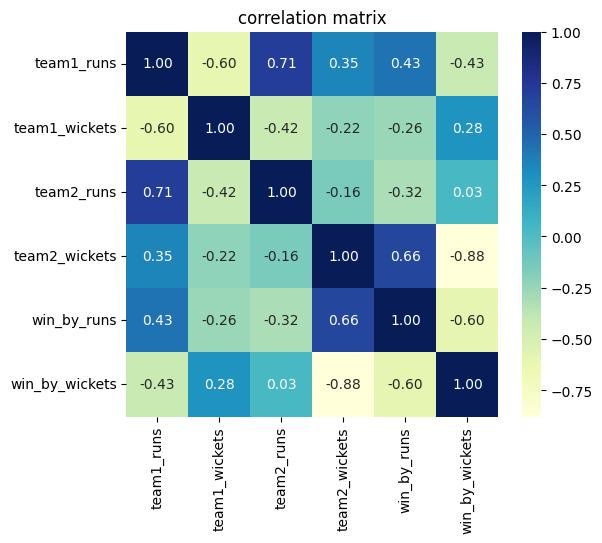

In [68]:
# checking the correlation

import seaborn as sns

correlation_matrix = X.corr()
plt.figure(figsize=(6,5))
sns.heatmap(
    correlation_matrix,
    annot = True ,
    cmap = 'YlGnBu' ,
    fmt = '0.2f'
)
plt.title("correlation matrix")
plt.show()

correlated features can combine into singular features under PCA

In [70]:
# standardizing the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled[:5]

array([[-1.08391445, -0.15457742, -0.69205175, -0.33882318, -0.60654104,
         0.55497124],
       [-0.83400598,  0.31746546, -0.42843263, -0.33882318, -0.60654104,
         0.55497124],
       [-0.8895412 ,  0.78950834, -0.42843263, -0.33882318, -0.60654104,
         0.55497124],
       [-0.02874534, -0.15457742,  0.47958877, -1.08475947, -0.60654104,
         1.17064247],
       [ 0.49883922, -1.09866318,  0.53817079,  0.03414497, -0.06043434,
        -0.98420682]])

In [71]:
X_scaled.mean().round(2)

np.float64(0.0)

In [72]:
X_scaled.std()

np.float64(1.0)

In [75]:
# applying PCA

pca = PCA(n_components = 2)
x_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(x_pca , columns = ['PC1' , 'PC2'])
pca_df.head()

,PC1,PC2
0,1.212677,-0.448880
1,1.234187,-0.340698
2,1.422036,-0.537371
3,1.271957,1.143354
4,-1.142919,0.767348


In [76]:
variance = pca.explained_variance_ratio_

print(f"PC1 : {variance[0] * 100 :.2f}%")
print(f"PC2 : {variance[1] * 100 :.2f}%")

print("total information retained : " , round(variance.sum() * 100 , 2) , "%")

PC1 : 49.08%
PC2 : 31.58%
total information retained :  80.66 %


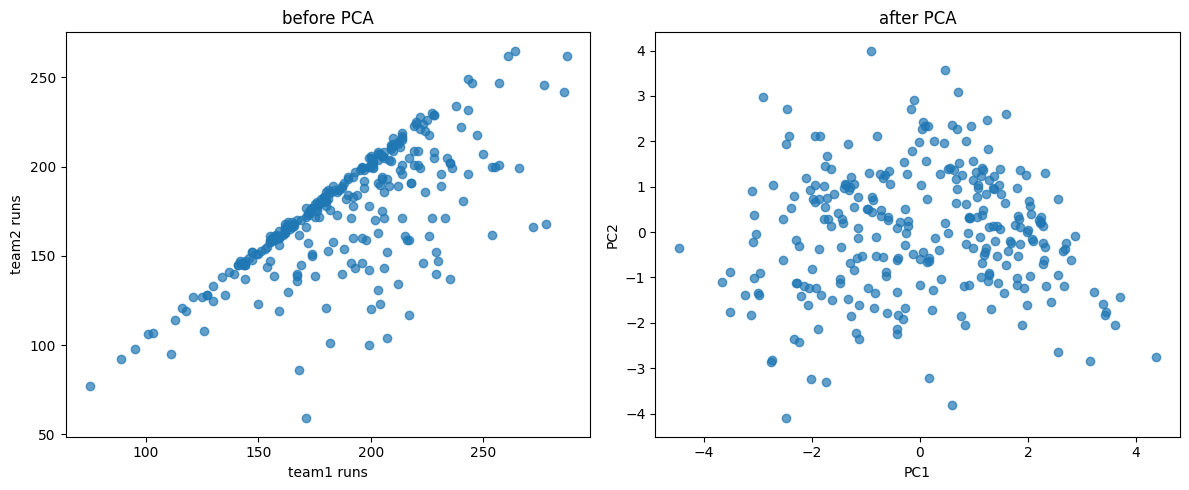

In [78]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.scatter(
    X['team1_runs'] ,
    X['team2_runs'] ,
    alpha = 0.7
)
plt.xlabel('team1 runs')
plt.ylabel('team2 runs')
plt.title('before PCA')

plt.subplot(1,2,2)
plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    alpha = 0.7
)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('after PCA')

plt.tight_layout()
plt.show()

data is now more normalized than it was before

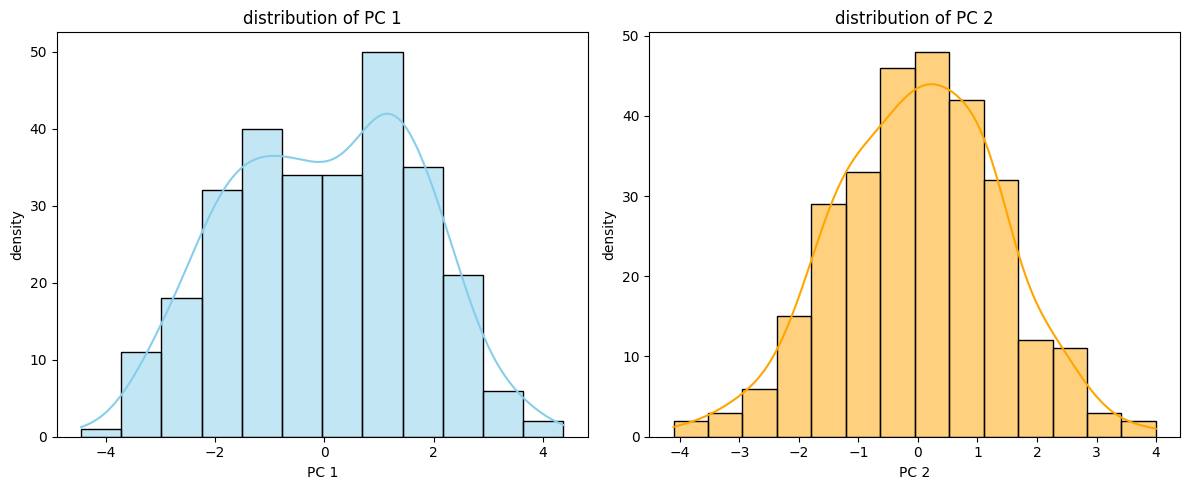

In [79]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(
    pca_df['PC1'],
    kde = True ,
    color = 'skyblue'
)
plt.xlabel('PC 1')
plt.ylabel('density')
plt.title('distribution of PC 1')

plt.subplot(1,2,2)
sns.histplot(
    pca_df['PC2'],
    kde = True ,
    color = 'orange'
)
plt.xlabel('PC 2')
plt.ylabel('density')
plt.title('distribution of PC 2')

plt.tight_layout()
plt.show()

key takeaways
- PCA reduces the number of features
- combines correlated features into principal components
-standardization is required before PCA
- PCA makes models faster and simplifies visualization